In [3]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.preprocessing import LabelEncoder, MultiLabelBinarizer

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [4]:
# Load datasets
sym_df = pd.read_csv("DiseaseAndSymptoms.csv")
pre_df = pd.read_csv("Disease precaution.csv")

print("Symptom Dataset Shape:", sym_df.shape)
print("Precaution Dataset Shape:", pre_df.shape)

Symptom Dataset Shape: (4920, 18)
Precaution Dataset Shape: (41, 5)


In [6]:
# EDA
print("EXPLORATORY DATA ANALYSIS")

# First five records
print("\nFirst 5 records:")
print(sym_df.head())

# Dataset information
print("\nDataset Information:")
sym_df.info()

# Missing values
print("\nMissing Values:")
print(sym_df.isnull().sum())

# Number of diseases
print("\nNumber of Unique Diseases:")
print(sym_df["Disease"].nunique())

# Disease names
print("\nDisease Classes:")
print(sym_df["Disease"].unique())

# Disease distribution
print("\nDisease Distribution:")
print(sym_df["Disease"].value_counts())


EXPLORATORY DATA ANALYSIS

First 5 records:
            Disease   Symptom_1              Symptom_2              Symptom_3  \
0  Fungal infection     itching              skin_rash   nodal_skin_eruptions   
1  Fungal infection   skin_rash   nodal_skin_eruptions    dischromic _patches   
2  Fungal infection     itching   nodal_skin_eruptions    dischromic _patches   
3  Fungal infection     itching              skin_rash    dischromic _patches   
4  Fungal infection     itching              skin_rash   nodal_skin_eruptions   

              Symptom_4 Symptom_5 Symptom_6 Symptom_7 Symptom_8 Symptom_9  \
0   dischromic _patches       NaN       NaN       NaN       NaN       NaN   
1                   NaN       NaN       NaN       NaN       NaN       NaN   
2                   NaN       NaN       NaN       NaN       NaN       NaN   
3                   NaN       NaN       NaN       NaN       NaN       NaN   
4                   NaN       NaN       NaN       NaN       NaN       NaN   

  Symp

In [8]:
# Clean Disease Names
sym_df["Disease"] = sym_df["Disease"].str.strip()
pre_df["Disease"] = pre_df["Disease"].str.strip()

In [9]:
# Check duplicates
print("\nNumber of duplicate rows:")
print(sym_df.duplicated().sum())


Number of duplicate rows:
4616


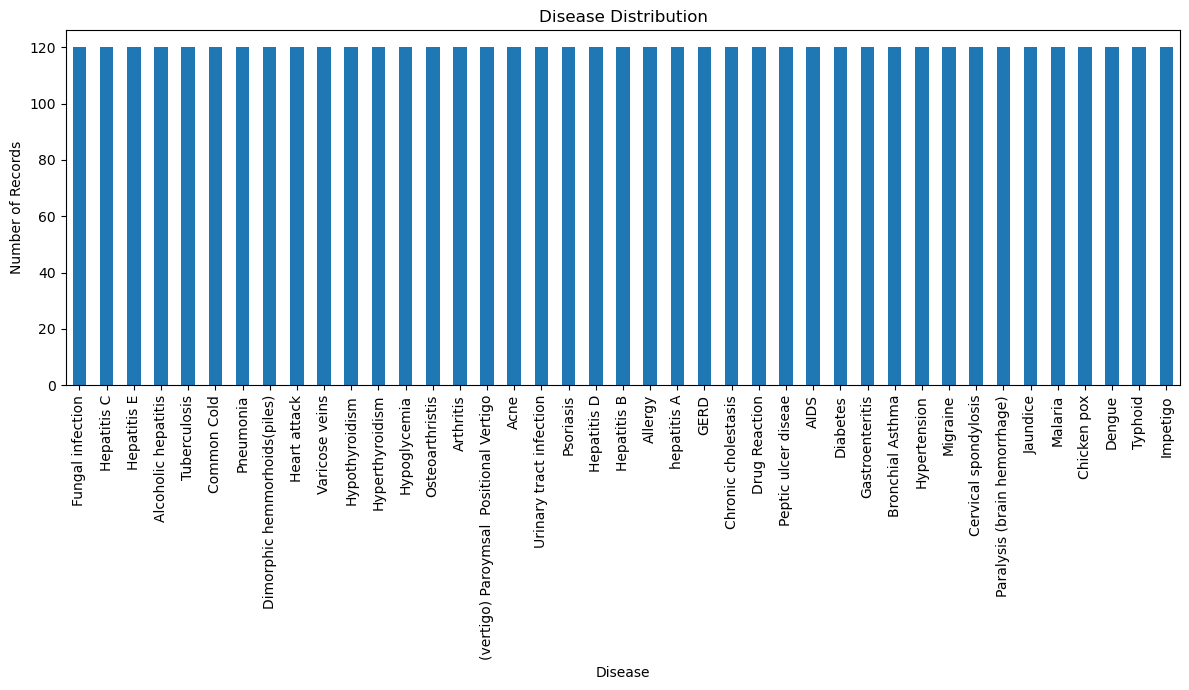

In [10]:
# Disease Distribution Graph
plt.figure(figsize=(12, 7))

sym_df["Disease"].value_counts().plot(kind="bar")

plt.title("Disease Distribution")
plt.xlabel("Disease")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [11]:
# Identify symptom columns
symptom_cols = [
    c for c in sym_df.columns
    if c.startswith("Symptom")
]

print("\nSymptom Columns:")
print(symptom_cols)


Symptom Columns:
['Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']


In [12]:
# Combine symptoms into a list
def get_symptoms(row):

    symptoms = []

    for col in symptom_cols:

        val = row[col]

        if pd.notna(val):

            symptom = (
                str(val)
                .strip()
                .replace(" ", "_")
                .lower()
            )

            symptoms.append(symptom)

    return symptoms


sym_df["symptom_list"] = sym_df.apply(
    get_symptoms,
    axis=1
)

In [13]:
# Remove duplicate disease symptom combinations
sym_df["symptom_str"] = sym_df["symptom_list"].apply(
    lambda x: ",".join(sorted(x))
)

sym_df = sym_df.drop_duplicates(
    subset=["Disease", "symptom_str"]
)

print(
    "\nUnique rows after deduplication:",
    len(sym_df)
)


Unique rows after deduplication: 304


In [14]:
# Get all unique symptoms
all_symptoms = set()

for symptom_list in sym_df["symptom_list"]:

    all_symptoms.update(symptom_list)

all_symptoms = sorted(list(all_symptoms))

print(
    "\nTotal Unique Symptoms:",
    len(all_symptoms)
)


Total Unique Symptoms: 131


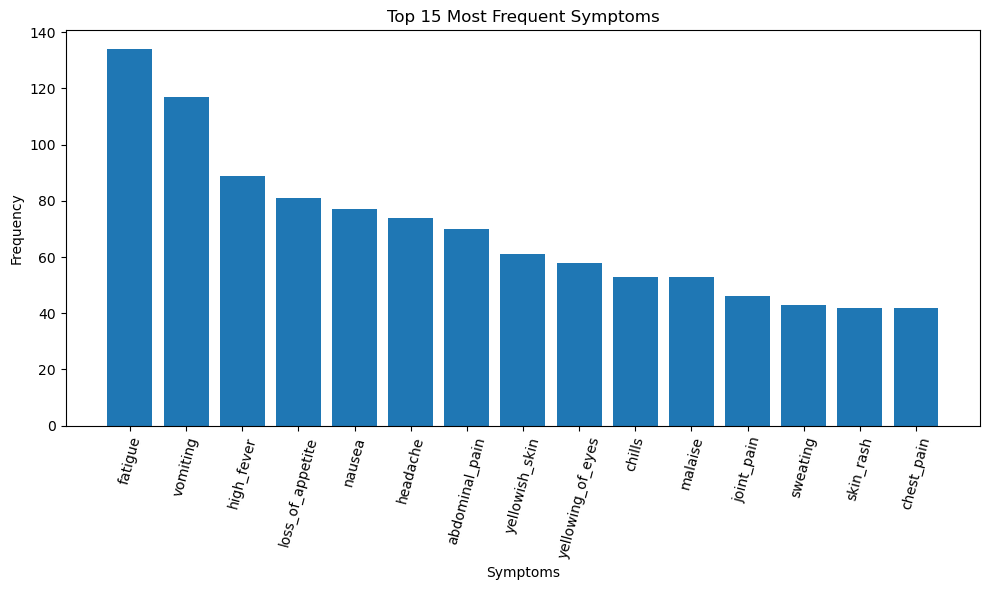

In [15]:
# Symptom frequency EDA
symptom_counter = Counter()

for symptom_list in sym_df["symptom_list"]:

    symptom_counter.update(symptom_list)

top_symptoms = symptom_counter.most_common(15)

symptom_names = [
    item[0] for item in top_symptoms
]

symptom_counts = [
    item[1] for item in top_symptoms
]


plt.figure(figsize=(10, 6))

plt.bar(
    symptom_names,
    symptom_counts
)

plt.title("Top 15 Most Frequent Symptoms")
plt.xlabel("Symptoms")
plt.ylabel("Frequency")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()



In [16]:
# Encode the original dataset
mlb = MultiLabelBinarizer(
    classes=all_symptoms
)

X_original = mlb.fit_transform(
    sym_df["symptom_list"]
)

label_encoder = LabelEncoder()

y_original = label_encoder.fit_transform(
    sym_df["Disease"]
)


print("\nOriginal Feature Matrix Shape:")
print(X_original.shape)

print("\nNumber of Disease Classes:")
print(len(label_encoder.classes_))


Original Feature Matrix Shape:
(304, 131)

Number of Disease Classes:
41


In [17]:
# Train test split
X_train_original, X_test, y_train_original, y_test = train_test_split(

    X_original,
    y_original,

    test_size=0.20,

    random_state=42,

    stratify=y_original
)


print("\nOriginal Training Samples:")
print(X_train_original.shape[0])

print("Original Testing Samples:")
print(X_test.shape[0])


Original Training Samples:
243
Original Testing Samples:
61


In [18]:
# Augment training data only
np.random.seed(42)

augmented_X = []
augmented_y = []


for i in range(len(X_train_original)):

    original_features = X_train_original[i]
    disease = y_train_original[i]

    # Add original training sample
    augmented_X.append(original_features)
    augmented_y.append(disease)

    # Get indexes of symptoms present in this sample
    symptom_indices = np.where(
        original_features == 1
    )[0]

    # Create partial symptom combinations
    if len(symptom_indices) >= 3:

        for _ in range(4):

            n_drop = np.random.randint(
                1,
                min(3, len(symptom_indices))
            )

            selected_indices = np.random.choice(
                symptom_indices,
                size=len(symptom_indices) - n_drop,
                replace=False
            )

            partial_features = np.zeros(
                len(all_symptoms),
                dtype=int
            )

            partial_features[selected_indices] = 1

            augmented_X.append(
                partial_features
            )

            augmented_y.append(
                disease
            )


X_train = np.array(augmented_X)
y_train = np.array(augmented_y)


print("\nTraining Dataset After Augmentation:")
print(X_train.shape)

print("Training Labels:")
print(y_train.shape)

print("\nTesting Dataset:")
print(X_test.shape)



Training Dataset After Augmentation:
(1215, 131)
Training Labels:
(1215,)

Testing Dataset:
(61, 131)


In [19]:
# Machine learning model comparison
models = {

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Naive Bayes":
        MultinomialNB(),

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

    "SVM":
        SVC(
            probability=True,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced"
        )
}

In [21]:
# Train and compare models
results = {}

trained_models = {}

print("MODEL COMPARISON")

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    results[name] = accuracy * 100

    trained_models[name] = model

    print(
        f"{name} Accuracy: "
        f"{accuracy * 100:.2f}%"
    )

MODEL COMPARISON

Training: Decision Tree
Decision Tree Accuracy: 98.36%

Training: Naive Bayes
Naive Bayes Accuracy: 98.36%

Training: Logistic Regression
Logistic Regression Accuracy: 100.00%

Training: SVM
SVM Accuracy: 100.00%

Training: Random Forest
Random Forest Accuracy: 100.00%


In [22]:
# Display model comparison
results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print("\nModel Comparison:")
print(results_df.to_string(index=False))


Model Comparison:
              Model   Accuracy
Logistic Regression 100.000000
                SVM 100.000000
      Random Forest 100.000000
      Decision Tree  98.360656
        Naive Bayes  98.360656


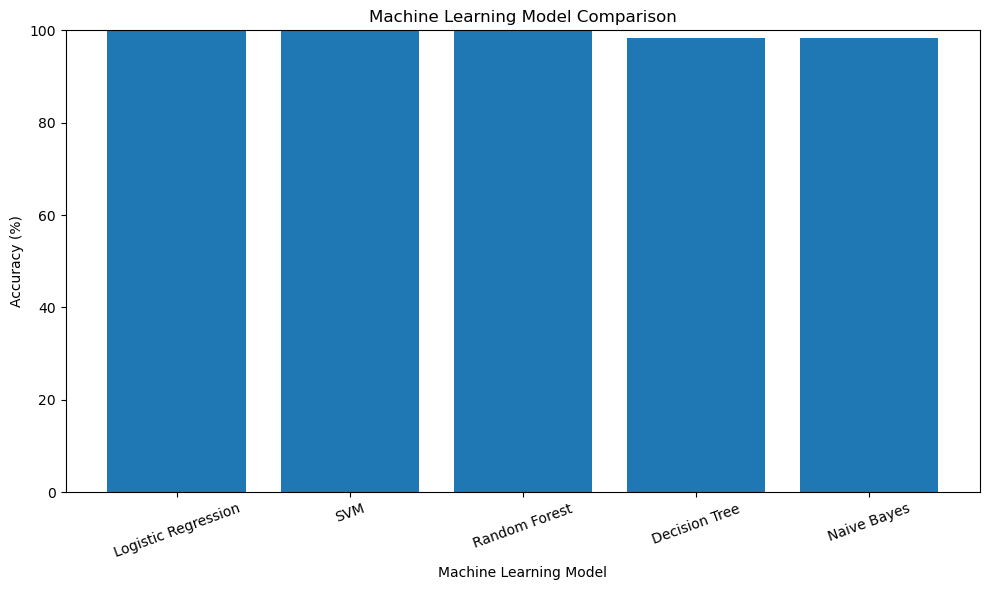

In [23]:
# Model comparison graph
plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [24]:
# Select random forest
rf_model = RandomForestClassifier(

    n_estimators=100,

    random_state=42,

    class_weight="balanced"
)

rf_model.fit(
    X_train,
    y_train
)

print(
    "\nRandom Forest model trained successfully."
)


Random Forest model trained successfully.


In [25]:
# Random forest test prediction
y_pred = rf_model.predict(
    X_test
)

In [26]:
# Test Accuracy
test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "\nRandom Forest Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)


Random Forest Test Accuracy: 100.00%


In [27]:
# Classification report
print("CLASSIFICATION REPORT")

print(
    classification_report(

        y_test,

        y_pred,

        target_names=label_encoder.classes_,

        zero_division=0
    )
)

CLASSIFICATION REPORT
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         2
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       1.00      1.00      1.00         2
                    Chronic cholestasis       1.00      1.00      1.00         2
                            Common Cold       1.00      1.00      1.00         2
     

In [29]:
# STRATIFIED 5-FOLD CROSS VALIDATION
print("5-FOLD STRATIFIED CROSS VALIDATION")
cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42
)


cv_scores = cross_val_score(

    rf_model,

    X_train,

    y_train,

    cv=cv,

    scoring="accuracy"
)


print("\nCross-Validation Results:")

for i, score in enumerate(
    cv_scores,
    start=1
):

    print(
        f"Fold {i}: "
        f"{score * 100:.2f}%"
    )


mean_cv_accuracy = cv_scores.mean()
std_cv_accuracy = cv_scores.std()


print(
    "\nMean Cross-Validation Accuracy:",
    f"{mean_cv_accuracy * 100:.2f}%"
)

print(
    "Cross-Validation Standard Deviation:",
    f"{std_cv_accuracy * 100:.2f}%"
)

5-FOLD STRATIFIED CROSS VALIDATION

Cross-Validation Results:
Fold 1: 99.59%
Fold 2: 97.94%
Fold 3: 99.18%
Fold 4: 98.77%
Fold 5: 99.59%

Mean Cross-Validation Accuracy: 99.01%
Cross-Validation Standard Deviation: 0.62%


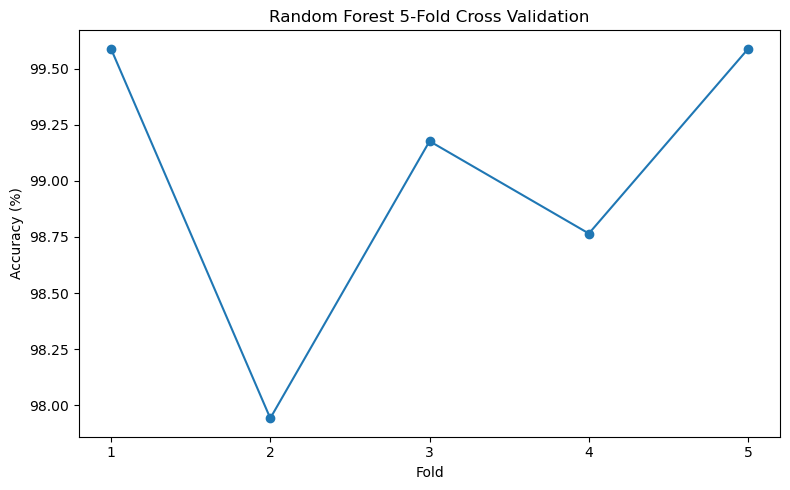

In [30]:
# CROSS-VALIDATION GRAPH
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 6),
    cv_scores * 100,
    marker="o"
)

plt.title(
    "Random Forest 5-Fold Cross Validation"
)

plt.xlabel("Fold")
plt.ylabel("Accuracy (%)")

plt.xticks(range(1, 6))

plt.tight_layout()
plt.show()

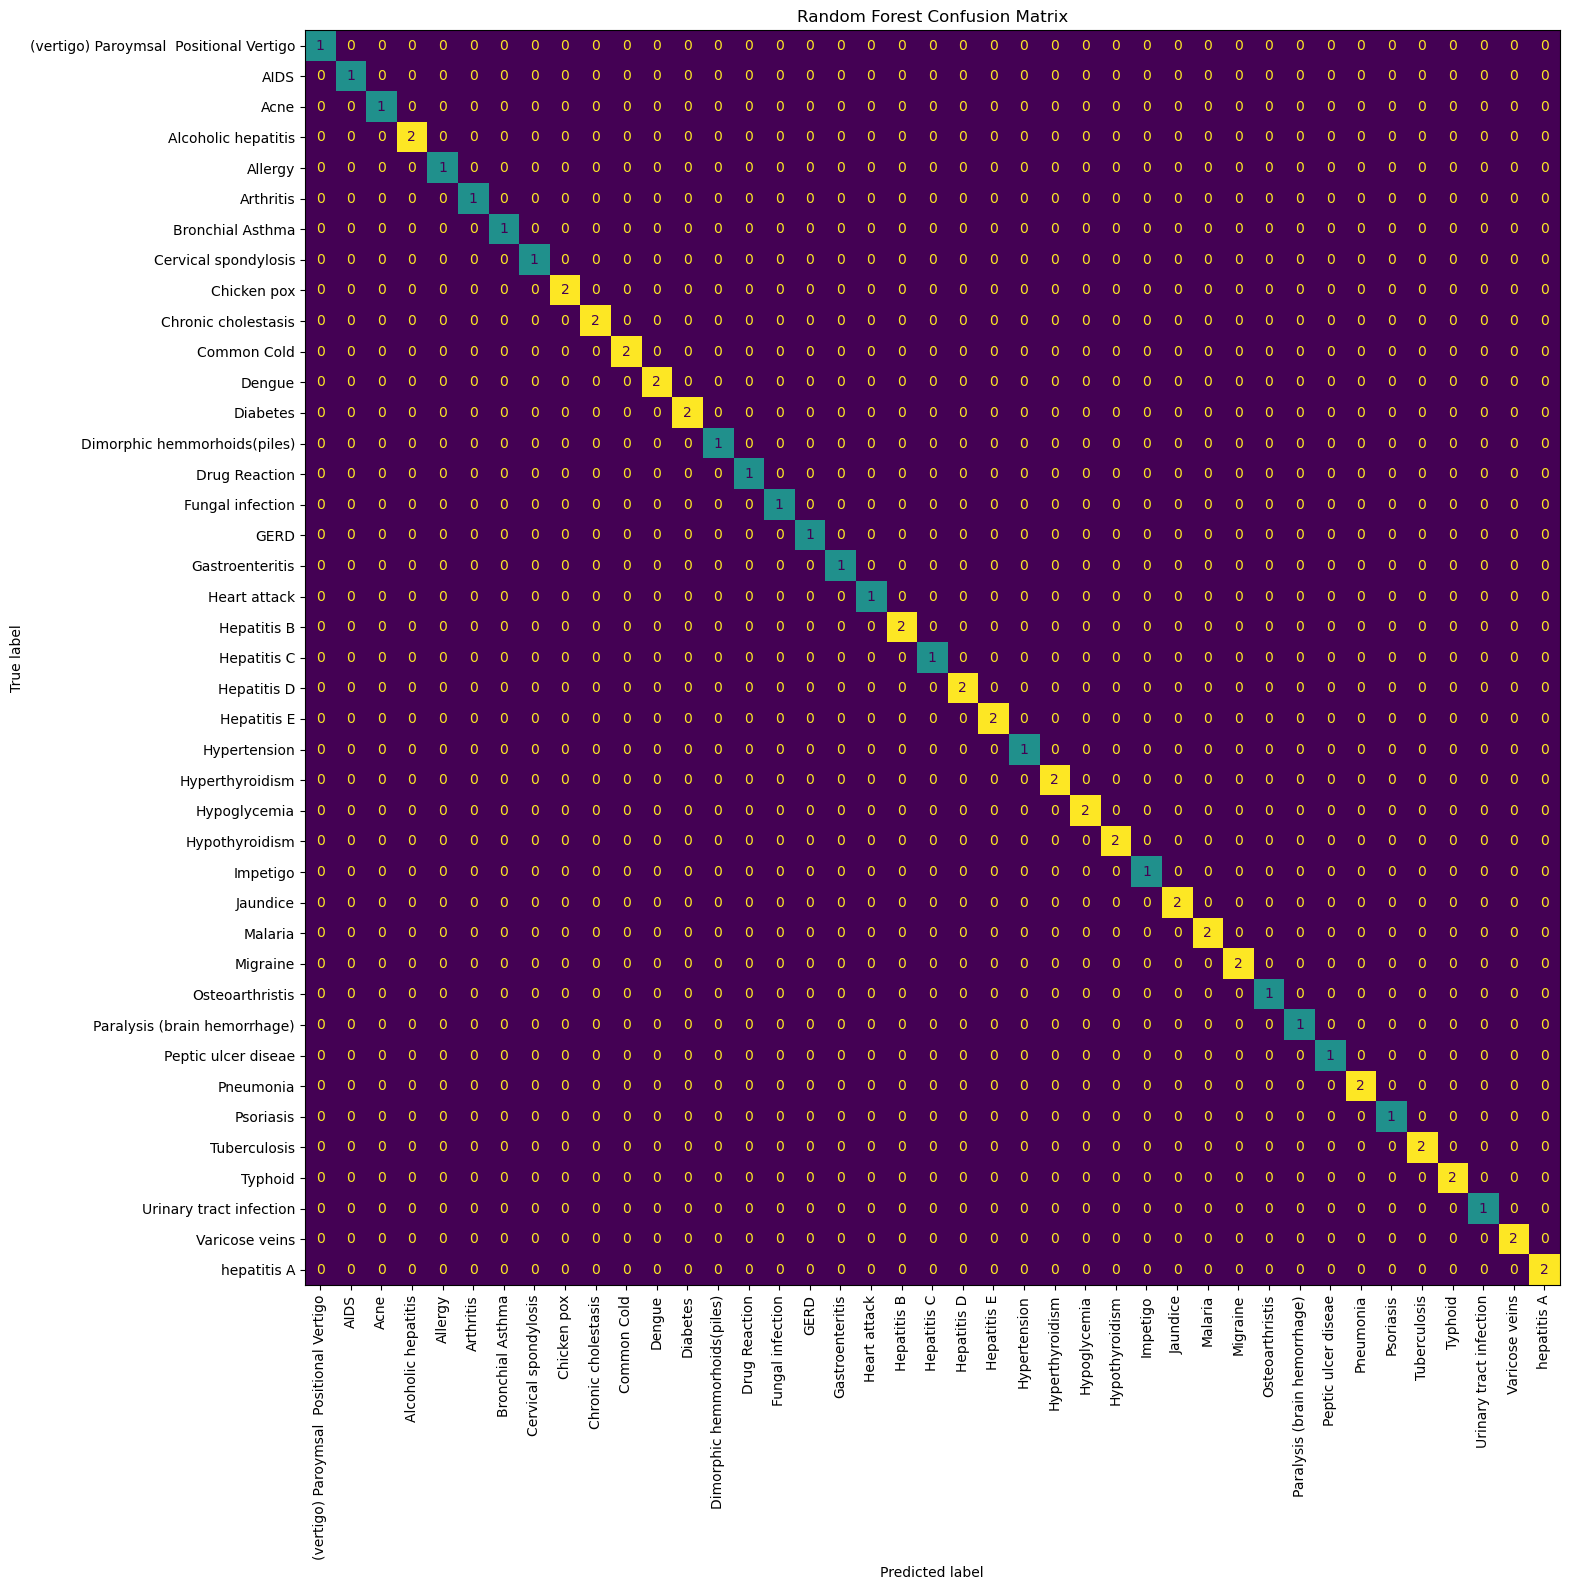

In [32]:
# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)


fig, ax = plt.subplots(
    figsize=(16, 16)
)


disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=label_encoder.classes_
)


disp.plot(

    ax=ax,

    xticks_rotation="vertical",

    values_format="d",

    colorbar=False
)


plt.title(
    "Random Forest Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [33]:
# RANDOM FOREST MODEL INFORMATION
print("FINAL RANDOM FOREST MODEL INFORMATION")
print(
    "Algorithm: Random Forest Classifier"
)

print(
    "Number of Trees:",
    rf_model.n_estimators
)

print(
    "Number of Features:",
    X_train.shape[1]
)

print(
    "Number of Disease Classes:",
    len(label_encoder.classes_)
)

print(
    "Original Training Samples:",
    X_train_original.shape[0]
)

print(
    "Augmented Training Samples:",
    X_train.shape[0]
)

print(
    "Testing Samples:",
    X_test.shape[0]
)

print(
    "Random State:",
    42
)


FINAL RANDOM FOREST MODEL INFORMATION
Algorithm: Random Forest Classifier
Number of Trees: 100
Number of Features: 131
Number of Disease Classes: 41
Original Training Samples: 243
Augmented Training Samples: 1215
Testing Samples: 61
Random State: 42


In [35]:
# SAVE FINAL MODEL
pickle.dump(
    rf_model,
    open("disease_model.pkl", "wb")
)

pickle.dump(
    mlb,
    open("mlb.pkl", "wb")
)

pickle.dump(
    label_encoder,
    open("label_encoder.pkl", "wb")
)
print("MODEL FILES SAVED")
print("disease_model.pkl")
print("mlb.pkl")
print("label_encoder.pkl")

MODEL FILES SAVED
disease_model.pkl
mlb.pkl
label_encoder.pkl


In [37]:
# FINAL SUMMARY
print("FINAL TRAINING SUMMARY")
print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Mean 5-Fold CV Accuracy: "
    f"{mean_cv_accuracy * 100:.2f}%"
)

print(
    f"CV Standard Deviation: "
    f"{std_cv_accuracy * 100:.2f}%"
)

print(
    f"Number of Symptoms: "
    f"{len(mlb.classes_)}"
)

print(
    f"Number of Diseases: "
    f"{len(label_encoder.classes_)}"
)

print(
    f"Number of Trees: "
    f"{rf_model.n_estimators}"
)

print("\nTraining completed successfully.")

FINAL TRAINING SUMMARY
Test Accuracy: 100.00%
Mean 5-Fold CV Accuracy: 99.01%
CV Standard Deviation: 0.62%
Number of Symptoms: 131
Number of Diseases: 41
Number of Trees: 100

Training completed successfully.
